[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

构建半加器与全加器，用 12 比特线路计算 3 + 5。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 量子加法器

入门示例使用 3 + 5，最大位宽为 3，下面的四组寄存器共需 12 个量子比特，预期输出 8。

<details>
<summary>扩展练习：更大的整数与模拟资源</summary>

可在具备足够资源时尝试 230 + 241。两者均为 8 位，当前构造需要 32 个量子比特。完整密集态矢量仅振幅存储，按 complex64 估算约 32 GiB，按 complex128 约 64 GiB，尚未计入缓冲区；这不是本例实测的内存峰值。降低 shots 不能消除态矢量随比特数增长的主要开销，因此默认不运行该大输入。

</details>

In [1]:
from pyqpanda3.core import X, CNOT, QProg, measure, CPUQVM, draw_qprog

In [2]:
def adder_2bit(a: int, b: int, s: int, c: int) -> QProg:
    prog = QProg()
    prog << X(c).control([a, b])
    prog << X(s).control(a)
    prog << X(s).control(b)
    return prog

In [3]:
def adder_3bit(ai: int, bi: int, ci: int, s: int, c: int) -> QProg:
    prog = QProg()
    prog << X(s).control(ai) << X(s).control(bi) << X(s).control(ci)
    prog << X(bi).control(ai) << X(ci).control(ai) << X(c).control([bi, ci])
    prog << X(c).control(ai) << X(ci).control(ai) << X(bi).control(ai)
    return prog

In [4]:
def adder_circuit(a: int, b: int) -> QProg:
    n = max(a.bit_length(), b.bit_length())  # 获取二进制数的位数
    Qa, Qb, Qs, Qc = list(range(n)), list(range(n, 2*n)), list(range(2*n, 3*n)), list(range(3*n, 4*n))

    prog = QProg(4 * n)  # 共用到4n个量子比特
    for i in range(n):
        a_i = (a >> i) & 1  # 获取a的第i位
        b_i = (b >> i) & 1  # 获取b的第i位
        if a_i:
            prog << X(Qa[i])  # a_i所在的量子比特索引
        if b_i:
            prog << X(Qb[i])  # b_i所在的量子比特索引

    prog << adder_2bit(Qa[0], Qb[0], Qs[0], Qc[0])
    for i in range(1, n):
        prog << adder_3bit(Qa[i], Qb[i], Qc[i-1], Qs[i], Qc[i])

    for i in range(n):
        prog << measure(Qs[i], i)
    prog << measure(Qc[-1], n)

    return prog

In [5]:
a, b = 3, 5
prog = adder_circuit(a, b)

In [6]:
qvm = CPUQVM()
qvm.run(prog, 100)
result = qvm.result().get_counts()
print(result)

for state, cnt in result.items():
	print(f"{a} + {b} 的计算结果为：", int(state, base=2))

{'1000': 100}
3 + 5 的计算结果为： 8


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

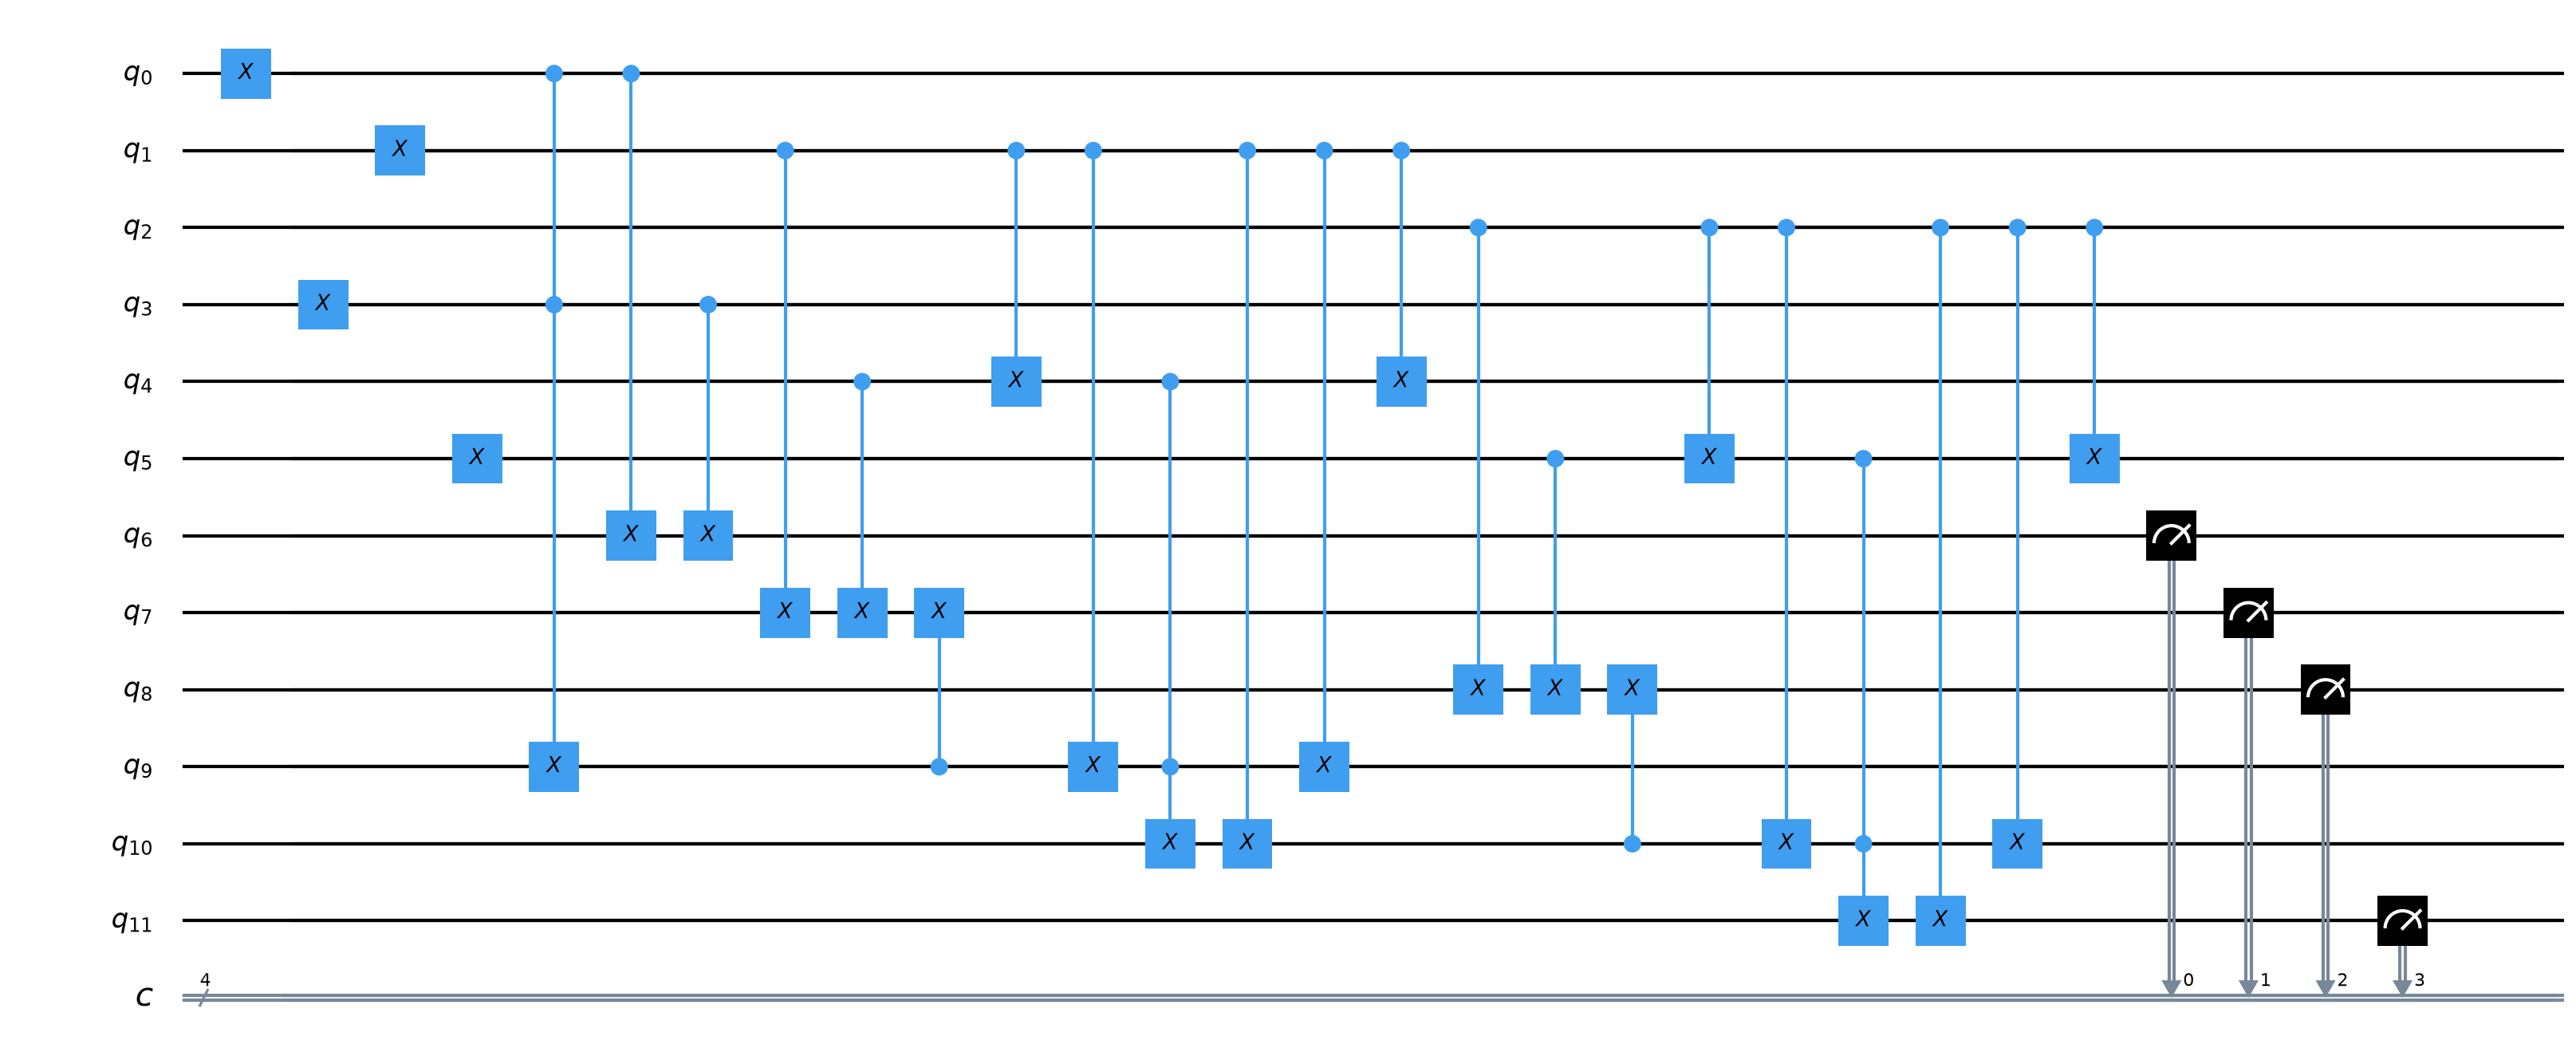

In [7]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day2"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "04_quantum_adder.png"
prog.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))
